<center><h1 style="color: #0f2fa2; white-space: pre-wrap;"><font size="6">Participez à la conception d'une voiture autonome</font></h1></center>

<center><h1 style="color: #0f2fa2; white-space: pre-wrap;"><font size="5">Segmentation d'image</font></h1></center>


__Future Vision Transport__ est une entreprise qui conçoit des systèmes embarqués de vision par ordinateur pour les véhicules autonomes.

La partie qui nous concerne et que nous traitons à travers ce notebook est la partie _segmentation d'images_. Pour développer notre modèle, nous avons à disposition le jeu de données [Cityscapes](https://www.cityscapes-dataset.com/dataset-overview/). Dans les grandes lignes, il s'agira de :
    
* Récupérer les données fournies et les enregistrer dans une structure adéquate de traitement
* Créer un générateur de données pour alimenter les modèles à entrainer
* Définir et entrainer des modèles de segmentation
* Introduire et évaluer l'impact d'une augmentation des données


## Sommaire

* [Pré-requis :  Imports et configurations](#partie0)
* [Partie I :  Sélection et ordonnancement des données](#partie1)
* [Partie II : Entraînement du modèle avec uniquement les données à disposition](#partie2)
* [Partie III : Entraînement du même modèle, mais avec augmentation des données](#partie3)
* [Conclusion : Comparaisons des différents résultats d'entraînement du modèle](#partie4)


## Pré-requis :  Imports et configurations <a class="anchor" id="partie0"></a>

In [1]:
!pip install -q drive

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.6/96.6 kB 2.0 MB/s eta 0:00:00a 0:00:01


In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
import os
current_directory = '/content/drive/MyDrive'

target_folder = 'P8/P8_segmentation_image/src'
target_path = os.path.join(current_directory, target_folder)

In [4]:
if os.path.exists(target_path) and os.path.isdir(target_path):
    os.chdir(target_path)
    print("Vous êtes maintenant dans le dossier:", target_folder)

Vous êtes maintenant dans le dossier: P8/P8_segmentation_image/src


In [5]:
# numpy et pandas pour la manipulation de données
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Suppression des alertes
import warnings
warnings.filterwarnings('ignore')

# Gestion des répertoire
import os
# import splitfolders

from time import time

# import shutil
# import re

from PIL import Image

import tensorflow as tf
from keras.preprocessing import image
from keras.metrics import MeanIoU
from keras.utils import load_img, img_to_array
from keras.callbacks import ModelCheckpoint, EarlyStopping


# Import des fonctions du projet
from travail.fonctions import *
from travail.generateur import data_generator, data_generator_aug, rotation
from travail.multiclassunet import Unet, unet_view
from travail.metrics import *

In [6]:
# projet_path = "C:/Users/lnkhe/Documents/OpenClassroom/IA/P8_LINKE_Henri"
projet_path = "/content/drive/MyDrive/P8"

## Partie 1 :  Sélection et ordonnancement des données <a class="anchor" id="partie1"></a>

Après avoir téléchargées les données accessibles depuis la page d'[OpenClassrooms](https://openclassrooms.com/fr/paths/188/projects/723/assignment), il faut les sélectionner et ordonner de manière souhaitée afin de pouvoir les exploiter. Cela est d'autant plus essentiel que les données présentent dans le dossier "test" semblent corrompus. Ainsi nous n'exploiterons que les données présentes dans le dossier "train". Nous répartirons les données qui nous intéressent dans trois dossiers. Un dossier pour les images originales, un dossier pour les fichiers json contenant les polygones, et un dossier contenant les masques qui correspondent aux images coloriées.

Ensuite, après visualisation nous choisirons d'utiliser les masques déjà prêts via les images en couleurs ou si nous préférons utiliser les polygones.

In [ ]:
# Images originales
src = "{}/P8_Cityscapes_leftImg8bit_trainvaltest/leftImg8bit/train".format(projet_path)
dest = "{}/Data/Images".format(projet_path)

if not os.path.exists(dest):
    os.makedirs(dest)

for path, subdirs, files in os.walk(src):
    for name in files:
        if re.match("^.*.png$",name):
            filename = os.path.join(path, name)
            shutil.copy2(filename, dest)
print("Récupération des informations des images téléchargés...")


# Images labellisées
src = "{}/P8_Cityscapes_gtFine_trainvaltest/gtFine/train".format(projet_path)
dest = "{}/Data/Labels".format(projet_path)

if not os.path.exists(dest):
    os.makedirs(dest)

for path, subdirs, files in os.walk(src):
    for name in files:
        if re.match("^.*_gtFine_labelIds.png$",name):
            filename = os.path.join(path, name)
            shutil.copy2(filename, dest)
print("Récupération des masques téléchargés...")

# Polygones
src = "{}/P8_Cityscapes_gtFine_trainvaltest/gtFine/train".format(projet_path)
dest = "{}/Data/Polygones".format(projet_path)

if not os.path.exists(dest):
    os.makedirs(dest)

for path, subdirs, files in os.walk(src):
    for name in files:
        if re.match("^.*.json$",name):
            filename = os.path.join(path, name)
            shutil.copy2(filename, dest)
print("Récupération des informations des polygones téléchargés...")

Récupération des informations des images téléchargés...
Récupération des masques téléchargés...
Récupération des informations des polygones téléchargés...


Maintenant que nous avons récupérez nos données, il faut vérifier chaque image originale ait bien ses informations correspondantes dans les autres dossiers. Commençons par voir la quantité d'images que nous avons récupéré et si les quantités sont bien identiques dans les différents dossiers.

In [ ]:
image_dir = "{}/Data/Images".format(projet_path)
image_list = os.listdir(image_dir)
print(f"Nombre d'images dans notre dossier de destination: {len(image_list)}")
label_dir = "{}/Data/Labels".format(projet_path)
label_list = os.listdir(label_dir)
print(f"Nombre d'images labelisées dans notre dossier de destination: {len(label_list)}")
poly_dir = "{}/Data/Polygones".format(projet_path)
poly_list = os.listdir(poly_dir)
print(f"Nombre de fichiers de polygones dans notre dossier de destination: {len(poly_list)}")

Nombre d'images dans notre dossier de destination: 2975
Nombre d'images labelisées dans notre dossier de destination: 2975
Nombre de fichiers de polygones dans notre dossier de destination: 2975


Et maintenant la concordance entre les données de chaque dossier

In [ ]:
print("Vérification de la concordance des images avec les autres fichiers...")
# S'assurer les listes de fichier sont bien rangées dans le même ordre
image_list.sort()
label_list.sort()
poly_list.sort()

# Vérification de la correspondance des listes
# Attention à enlever la fin du nom de fichier et non de partir du début
# pour éviter les problèmes de longueurs de nom et type de fichier
for i in range(len(image_list)):
    assert image_list[i][:-16] == label_list[i][:-20], f"Problème rencontré sur l'item {i}"

for i in range(len(image_list)):
    assert image_list[i][:-16] == poly_list[i][:-21], f"Problème rencontré sur l'item {i}"



Vérification de la concordance des images avec les autres fichiers...


Les images et leur fichier de labels associé sont donc bien arrivés à destination dans le repertoire choisi. Une visualisation de ces éléments pourra nous donner une meilleur des éléments avec lesquels nous travaillons

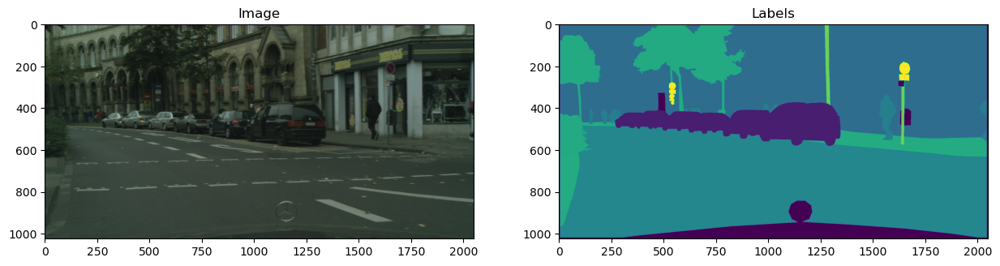

In [ ]:
# Essaie de représentation d'une image et de ses labels
i =100

image_sample = image.img_to_array(image.load_img(f"{image_dir}/{image_list[i]}"))/255.
color_sample = image.img_to_array(image.load_img(f"{color_dir}/{color_list[i]}",
                                                color_mode="grayscale"),
                                  dtype='uint8'
                                 )
color_sample = np.squeeze(color_sample)
fig = plt.figure(figsize=(15,15))
ax = fig.add_subplot(1, 2, 1)
ax.set_title('Image')
ax.imshow(image_sample)

ax1 = fig.add_subplot(1, 2, 2)
ax1.set_title('Labels')
ax1.imshow(color_sample)
plt.show()

Avant de savoir si on va utiliser les polygones pour colorier les images selon nos critères ou bien les images déjà colorier, on va faire une rapide comparaison visuelle entre les 2 afin de savoir si on peut tout de suite récupérer les images coloriées, ou s'il vaut mieux faire ce travail nous même.

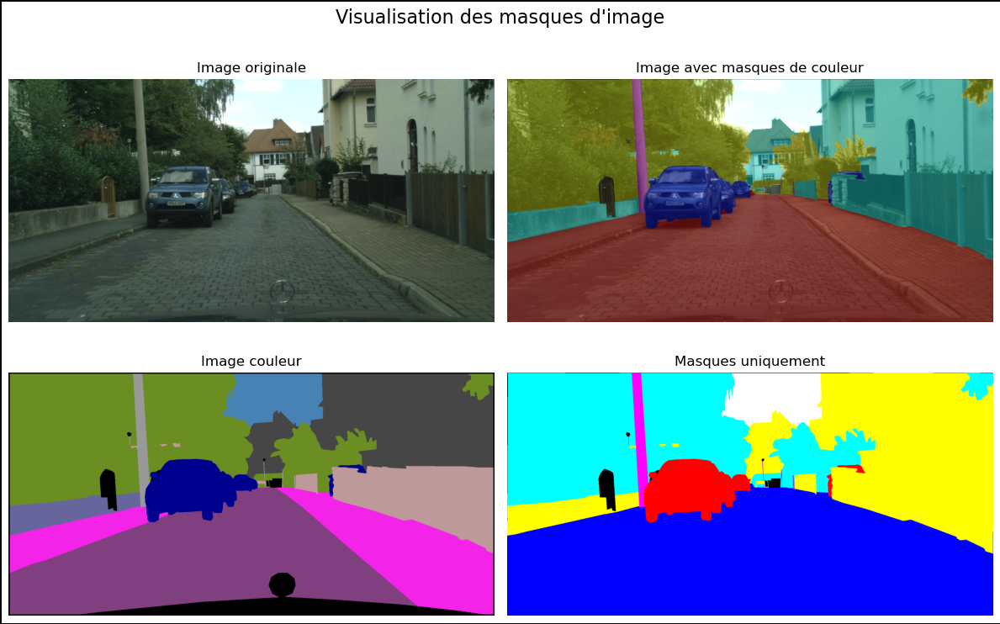

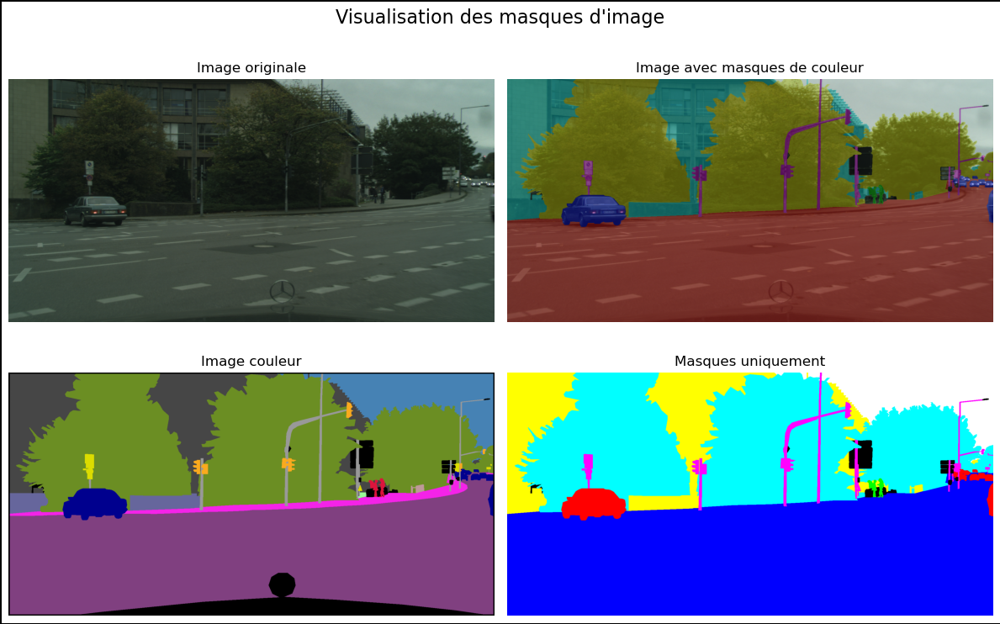

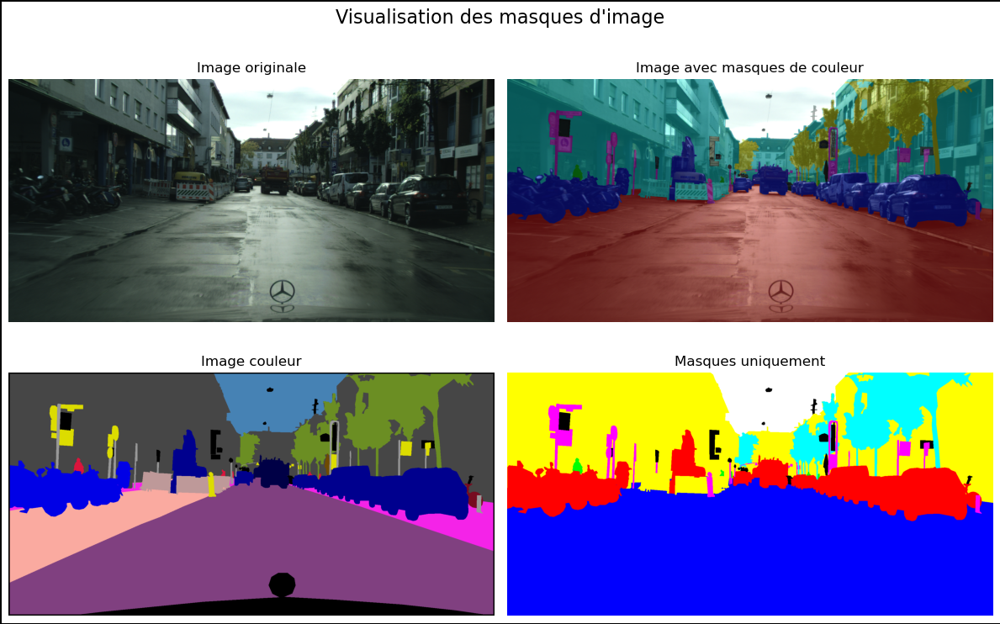

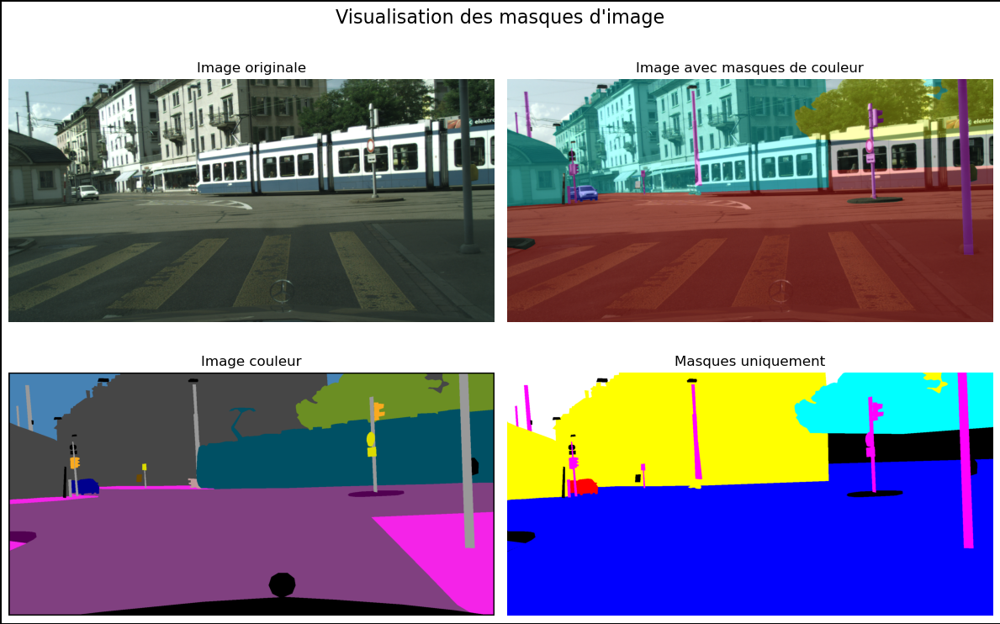

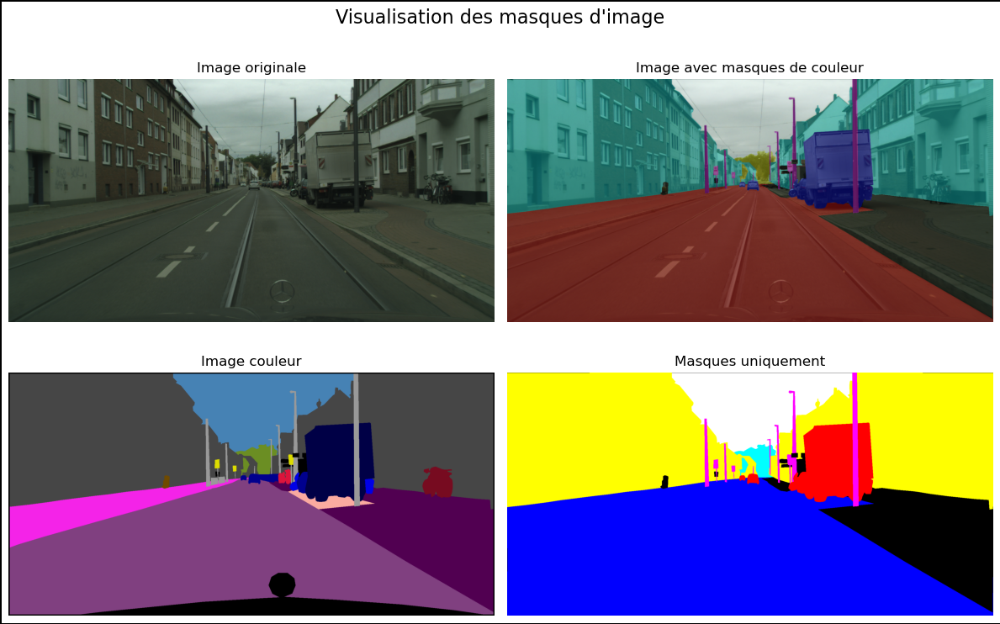

In [ ]:
n = 5

random_image = np.random.choice(range(len(image_list)), size=n, replace=False)

# for i in random_image:
for i in random_image:
    # Exemple d'utilisation
    json_file_path = f"{poly_dir}/{poly_list[i]}"
    image_file_path = f"{image_dir}/{image_list[i]}"
    color_file_path = f"{color_dir}/{color_list[i]}"


    add_color_masks_from_json(json_file_path, image_file_path, color_file_path)

On peut constater que les images déjà coloriées présentent plus de détails colorimétriques. Cela vient en partie du fait que nous avons regrouper nos classes par groupes. *Ainsi nous ne faisons pas la distinction entre les trotoirs et la route par exemple.*

Bien que nous n'ayons besoin de séparer que les 8 groupes, **nous utiliserons tout de même les images coloriées** par souci de simplicité et dans l'espoir d'avoir des images segmenter plus précisément si nous arrivons à avoir un modèle performant. D'autant que l'on peut constater des imperfections dans les masques obtenus à partir des polygones. Par exemple le tramway qui n'apparaît pas sur le masque.

Afin de pouvoir exploiter nos masques de couleurs dans un format compréhensible par le réseau de neurone, on va convertir nos masques qui sont actuellement en couleurs. Nous allons les convertir en nuances de gris choisies afin de pouvoir faire la démarche inverse. Ces images seront plus rapidement utilisable pour l'entraînement des modèles : il ne restera plus que la partie *one-hot-encoding* qui sera traitée au sein de la fonction génératrice.

In [ ]:
from PIL import Image
import os
import numpy as np

def convert_images_to_color(image_folder, output_folder, color_dict):
    """
    Convertit les images en couleurs en images avec des valeurs basées sur le dictionnaire de couleurs.

    :param image_folder: Chemin du dossier contenant les images en couleurs.
    :param output_folder: Chemin du dossier où enregistrer les images converties.
    :param color_dict: Dictionnaire de couleurs pour la conversion.

    """
    if not os.path.exists(output_folder):
        os.makedirs(output_folder)

    image_filenames = os.listdir(image_folder)

    for image_name in image_filenames:
        image_path = os.path.join(image_folder, image_name)

        # Charger et prétraiter l'image
        img = image.load_img(image_path, target_size=(512, 1024))
        img_array = image.img_to_array(img, dtype='uint8')

        # Créer une nouvelle image avec les valeurs basées sur le dictionnaire de couleurs
        new_img_array = np.zeros_like(img_array)
        for key, value in color_dict.items():
            indices = np.where(np.all(img_array == value, axis=-1))
            new_img_array[indices] = int(key)

        # Enregistrer la nouvelle image dans le dossier de sortie
        new_img = Image.fromarray(new_img_array.squeeze().astype('uint8'))
        new_image_name = os.path.splitext(image_name)[0] + '_converted.png'
        new_image_path = os.path.join(output_folder, new_image_name)
        new_img.save(new_image_path)

In [ ]:
path_orig = r"C:\Users\lnkhe\Documents\OpenClassroom\IA\P8_LINKE_Henri\Data\Labels"
path_dest = r"C:\Users\lnkhe\Documents\OpenClassroom\IA\P8_LINKE_Henri\Data\New_labels"

In [ ]:
original_color = {
    '0': [0, 0, 0], '1': [0, 0, 70], '2': [0, 0, 90], '3': [0, 0, 110], '4': [0, 0, 142], '5': [0, 0, 230],
    '6': [0, 60, 100], '7': [0, 80, 100], '8': [70, 70, 70], '9': [70, 130, 180], '10': [81, 0, 81],
    '11': [102, 102, 156], '12': [107, 142, 35], '13': [111, 74, 0], '14': [119, 11, 32], '15': [128, 64, 128],
    '16': [150, 100, 100], '17': [150, 120, 90], '18': [152, 251, 152], '19': [153, 153, 153], '20': [180, 165, 180],
    '21': [190, 153, 153], '22': [220, 20, 60], '23': [220, 220, 0], '24': [230, 150, 140], '25': [244, 35, 232],
    '26': [250, 170, 30], '27': [250, 170, 160], '28': [255, 0, 0]
}

In [ ]:
convert_images_to_color(path_orig, path_dest, original_color)

Pour éviter les fuites d'informations, il nous faut maintenant créer des dossiers spécifiques à l'entraînement, à la validation et aux tests dans lesquels répartir nos données.

Nous allons pour cela utiliser le module *splitfolders* qui traite cela automatiquement. Une fois que cela sera fait, il faudra vérifier que nous ayons bien correspondance entre les photos et les labels que nous pourront indifféremment appeler __masques__ à partir de maintenant.

In [ ]:
split_data_path = "{}/Split_data".format(projet_path)
data_p8_path = "{}/Data".format(projet_path)
# splitfolders.ratio(data_p8_path, output=split_data_path, seed =0, ratio=(.8,0.1, 0.1))

In [ ]:
# Images d'entrainement
img_train_dir = '{}/train/Images'.format(split_data_path)
lab_train_dir = '{}/train/Labels'.format(split_data_path)
img_train_list = os.listdir(img_train_dir)
lab_train_list = os.listdir(lab_train_dir)
img_train_list.sort()
lab_train_list.sort()

# Image de test
img_test_dir = '{}/test/Images'.format(split_data_path)
lab_test_dir = '{}/test/Labels'.format(split_data_path)
img_test_list = os.listdir(img_test_dir)
lab_test_list = os.listdir(lab_test_dir)
img_test_list.sort()
lab_test_list.sort()

# Image de validation
img_val_dir = '{}/val/Images'.format(split_data_path)
lab_val_dir = '{}/val/Labels'.format(split_data_path)
img_val_list = os.listdir(img_val_dir)
lab_val_list = os.listdir(lab_val_dir)
img_val_list.sort()
lab_val_list.sort()

print(f"Nombre d'images d'entrainement: {len(img_train_list)}\n\
Nombre de fichiers de labels d'entrainement: {len(lab_train_list)}\n\
Nombre d'images de test: {len(img_test_list)}\n\
Nombre de fichiers de labels de test: {len(lab_test_list)}\n\
Nombre d'images de validation: {len(img_val_list)}\n\
Nombre de fichiers de labels de validation: {len(lab_val_list)}")

Nombre d'images d'entrainement: 2380
Nombre de fichiers de labels d'entrainement: 2380
Nombre d'images de test: 298
Nombre de fichiers de labels de test: 298
Nombre d'images de validation: 297
Nombre de fichiers de labels de validation: 297


In [ ]:
print("Vérification de la concordance des images et des fichiers de labels...")
for i in range(len(img_train_list)):
    assert img_train_list[i][:-16] == lab_train_list[i][:-27],\
     f"Problème rencontré sur l'item {i}" #pour trouver l'erreur au besoin
for i in range(len(img_test_list)):
    assert img_test_list[i][:-16] == lab_test_list[i][:-27],\
     f"Problème rencontré sur l'item {i}" #pour trouver l'erreur au besoin
for i in range(len(img_val_list)):
    assert img_val_list[i][:-16] == lab_val_list[i][:-27],\
     f"Problème rencontré sur l'item {i}" #pour trouver l'erreur au besoin

print('Les données correspondent bien.')

Vérification de la concordance des images et des fichiers de labels...
Les données correspondent bien.


## Partie II : Entraînement du modèle avec uniquement les données à disposition <a class="anchor" id="partie2"></a>

La fonction génératrice et le modèle sont importés. Il ne reste qu'à définir tous les paramètres utiles à la fonction génératrice et au modèle.

In [ ]:
split_data_path = "{}/Split_data".format(projet_path)

# Images d'entrainement
img_train_dir = '{}/train/Images'.format(split_data_path)
lab_train_dir = '{}/train/Labels'.format(split_data_path)

# Image de validation
img_val_dir = '{}/val/Images'.format(split_data_path)
lab_val_dir = '{}/val/Labels'.format(split_data_path)

# Image de test
img_test_dir = '{}/test/Images'.format(split_data_path)
lab_test_dir = '{}/test/Labels'.format(split_data_path)

In [ ]:
param_unet = {
    "img_height": 256,
    "img_width": 512
}

param_train_gen = {
    "image_folder": img_train_dir,
    "mask_folder": lab_train_dir,
    "batch_size": 8,
    "img_height": 256,
    "img_width": 512
}

param_val_gen = {
    "image_folder": img_val_dir,
    "mask_folder": lab_val_dir,
    "batch_size": 8,
    "img_height": 256,
    "img_width": 512
}

param_fit = {
    "epochs": 25,
    "steps_per_epoch": len(os.listdir(param_train_gen['image_folder'])) // param_train_gen['batch_size'],
    "validation_steps": len(os.listdir(param_val_gen['image_folder'])) // param_val_gen['batch_size']
}


On définit ici le modèle

In [ ]:
# Initialisation du modèle
model_unet = Unet(**param_unet)


# Créer des générateurs de données pour l'entraînement et la validation
train_generator = data_generator(**param_train_gen)
val_generator = data_generator(**param_val_gen)


# model_unet.compile(optimizer=optimizer, loss=total_loss, metrics=[MeanIoU(num_classes=29)])
model_unet.compile(optimizer='adam', loss='categorical_crossentropy', metrics=[dice_coeff, 'accuracy'])


In [ ]:
model_unet.summary()

Model: "Unet"
__________________________________________________________________________________________________
 Layer (type)                   Output Shape         Param #     Connected to                     
 image_input (InputLayer)       [(None, 256, 512, 3  0           []                               
                                )]                                                                
                                                                                                  
 conv2d (Conv2D)                (None, 256, 512, 64  1792        ['image_input[0][0]']            
                                )                                                                 
                                                                                                  
 batch_normalization (BatchNorm  (None, 256, 512, 64  256        ['conv2d[0][0]']                 
 alization)                     )                                                              

Lancement d'un premier entraînement depuis zéro avec des métriques "grossière". Tous les autres entraînement se baseront sur le meilleur résultat de celui-ci. A savoir l'entraînement de ce même modèle avec et sans augmentation de données, mais avec des métriques plus "fine", plus adaptée à notre problème de segmentation.

In [ ]:
from keras.callbacks import ModelCheckpoint, EarlyStopping

# Définition des callbacks
checkpoint = ModelCheckpoint("best_model.h5", monitor="dice_coeff", mode="max", save_best_only=True)
early_stopping = EarlyStopping(monitor='dice_coeff', mode="max", patience=5, verbose=1)

# Entraînement du modèle avec les callbacks
history = model_unet.fit(train_generator, validation_data=val_generator, callbacks=[checkpoint, early_stopping], **param_fit)


Epoch 1/25
297/297 [==============================] - 1522s 5s/step - loss: 1.7597 - dice_coeff: 0.2627 - accuracy: 0.6978 - val_loss: 1.6072 - val_dice_coeff: 0.3350 - val_accuracy: 0.7294
Epoch 2/25
297/297 [==============================] - 357s 1s/step - loss: 1.1453 - dice_coeff: 0.4487 - accuracy: 0.7954 - val_loss: 1.0372 - val_dice_coeff: 0.5267 - val_accuracy: 0.8045
Epoch 3/25
297/297 [==============================] - 359s 1s/step - loss: 0.8835 - dice_coeff: 0.5666 - accuracy: 0.8230 - val_loss: 0.7729 - val_dice_coeff: 0.6450 - val_accuracy: 0.8379
Epoch 4/25
297/297 [==============================] - 354s 1s/step - loss: 0.7457 - dice_coeff: 0.6392 - accuracy: 0.8363 - val_loss: 0.6776 - val_dice_coeff: 0.6995 - val_accuracy: 0.8413
Epoch 5/25
297/297 [==============================] - 353s 1s/step - loss: 0.6553 - dice_coeff: 0.6882 - accuracy: 0.8475 - val_loss: 0.6769 - val_dice_coeff: 0.6920 - val_accuracy: 0.8357
Epoch 6/25
297/297 [==============================] - 

In [ ]:
with tf.keras.utils.custom_object_scope({'dice_coeff': dice_coeff, 'total_loss': total_loss}):
    model_unet = tf.keras.models.load_model("best_model_2.h5")

# Afficher le résumé du modèle
model_unet.summary()

Model: "Unet"
__________________________________________________________________________________________________
 Layer (type)                   Output Shape         Param #     Connected to                     
 image_input (InputLayer)       [(None, 256, 512, 3  0           []                               
                                )]                                                                
                                                                                                  
 conv2d_19 (Conv2D)             (None, 256, 512, 64  1792        ['image_input[0][0]']            
                                )                                                                 
                                                                                                  
 batch_normalization_19 (BatchN  (None, 256, 512, 64  256        ['conv2d_19[0][0]']              
 ormalization)                  )                                                              

On poursuie l'entraînement du modèle de segmentation en utilisant le même générateur de données, sans augmentation de données supplémentaires. Cependant, afin d'affiner les performances de notre modèle dans le contexte de la segmentation, on fournit les deux métriques d'évaluation adaptées suivantes : le coefficient de Dice (Dice coefficient) et la Mean Intersection over Union (MeanIoU).

1. **Coefficient de Dice (Dice coefficient) :**
    
    Le coefficient de Dice mesure la similarité globale entre la prédiction et la vérité terrain pour une seule classe ou une seule région d'intérêt.

2. **Mean Intersection over Union (MeanIoU) :**

    La MeanIoU fournit une évaluation de la qualité de la segmentation pour chaque classe individuellement, puis moyenne ces valeurs pour donner une mesure globale de la performance du modèle.

In [ ]:
param_fit = {
    "epochs": 15,
    "steps_per_epoch": len(os.listdir(param_train_gen['image_folder'])) // param_train_gen['batch_size'],
    "validation_steps": len(os.listdir(param_val_gen['image_folder'])) // param_val_gen['batch_size']
}

# Créer des générateurs de données pour l'entraînement et la validation
train_generator = data_generator(**param_train_gen)
val_generator = data_generator(**param_val_gen)


# model_unet.compile(optimizer=optimizer, loss=total_loss, metrics=[MeanIoU(num_classes=29)])
model_unet.compile(optimizer='adam', loss=total_loss, metrics=[dice_coeff, MeanIoU(num_classes=29)])

# Définition des callbacks
checkpoint = ModelCheckpoint("best_model_2.h5", monitor="dice_coeff", mode="max", save_best_only=True)
early_stopping = EarlyStopping(monitor='dice_coeff', mode="max", patience=5, verbose=1)

# Entraînement du modèle avec les callbacks
history = model_unet.fit(train_generator, validation_data=val_generator, callbacks=[checkpoint, early_stopping], **param_fit)


Epoch 1/15
297/297 [==============================] - 370s 1s/step - loss: 0.6362 - dice_coeff: 0.8922 - mean_io_u: 0.4716 - val_loss: 0.6972 - val_dice_coeff: 0.8462 - val_mean_io_u: 0.4718
Epoch 2/15
297/297 [==============================] - 352s 1s/step - loss: 0.5413 - dice_coeff: 0.8978 - mean_io_u: 0.4726 - val_loss: 0.5555 - val_dice_coeff: 0.8808 - val_mean_io_u: 0.4732
Epoch 3/15
297/297 [==============================] - 356s 1s/step - loss: 0.4806 - dice_coeff: 0.9026 - mean_io_u: 0.4736 - val_loss: 0.4997 - val_dice_coeff: 0.8880 - val_mean_io_u: 0.4723
Epoch 4/15
297/297 [==============================] - 352s 1s/step - loss: 0.4377 - dice_coeff: 0.9060 - mean_io_u: 0.4753 - val_loss: 0.4712 - val_dice_coeff: 0.8912 - val_mean_io_u: 0.4744
Epoch 5/15
297/297 [==============================] - 352s 1s/step - loss: 0.4103 - dice_coeff: 0.9070 - mean_io_u: 0.4777 - val_loss: 0.4448 - val_dice_coeff: 0.8930 - val_mean_io_u: 0.4775
Epoch 6/15
297/297 [=========================

On complète le modèle à l'aide de la fonction unet_view afin que la sortie de l'image corresponde au masque de couleur initial.
Ensuite on effectue une première prédiction sur une image.

In [ ]:
model_complet = unet_view(model_unet)

In [ ]:
img_height, img_width = 256, 512


# Chargement et prétraitement d'une image pour la prédiction
image_path = os.path.join(img_test_dir, os.listdir(img_test_dir)[0])
img = load_img(image_path, target_size=(img_height, img_width))
img_array = img_to_array(img)
img_array = np.expand_dims(img_array, axis=0)  # Ajouter une dimension pour le lot (batch)

# Effectuer la prédiction
predicted_masks = model_complet.predict(img_array)

1/1 [==============================] - 10s 10s/step


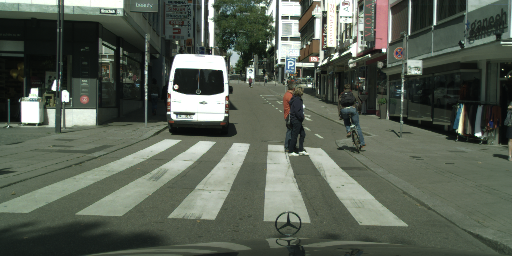

In [ ]:
img

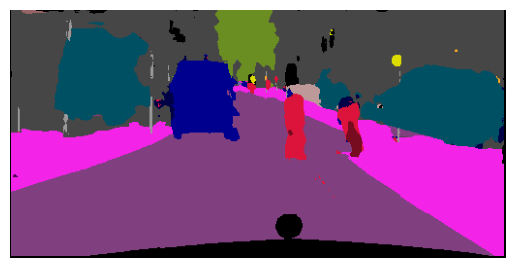

In [ ]:
predicted_masks = np.squeeze(predicted_masks)

import matplotlib.pyplot as plt

# Supposons que 'image_array' est le tableau NumPy obtenu après la transformation
# Assurez-vous que 'image_array' a la forme (img_height, img_width, 3)
plt.imshow(predicted_masks.astype('uint8'))
plt.axis('off')  # Masquer les axes
plt.show()

## Partie III : Entraînement du même modèle, mais  avec augmentation des données <a class="anchor" id="partie3"></a>

Pour commencer voici un apperçu de l'augmentation de données. Plusieurs transformations aléatoires sont effectuées sur l'images tels que des rotations zoom changement de contrastes, ajout de bruit ... Cela permet au modèle d'avoir des données sans cesse renouvelées pour l'entraînement du modèle.

On s'attend donc à ce que l'entraînement du modèle soit lent avec des performances moindre, mais que le modèle puisse s'entraîner plus longuement tout en évitant le sur-apprentissage avec in-fine, de meilleures performances.

La difficulté principale dans les transformartions aléatoires est que les transformations qui touchent à l'espace, doivent être les mêmes pour les images et leur masque.

In [ ]:
list_img = os.listdir(img_train_dir)[16:19]

list_lab = [os.path.join(lab_train_dir, im[:-16]) + '_gtFine_color_converted.png' for im in list_img]
list_img = [os.path.join(img_train_dir, im) for im in list_img]

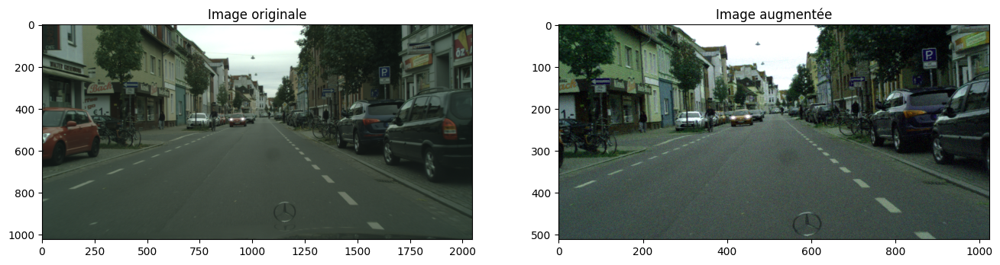

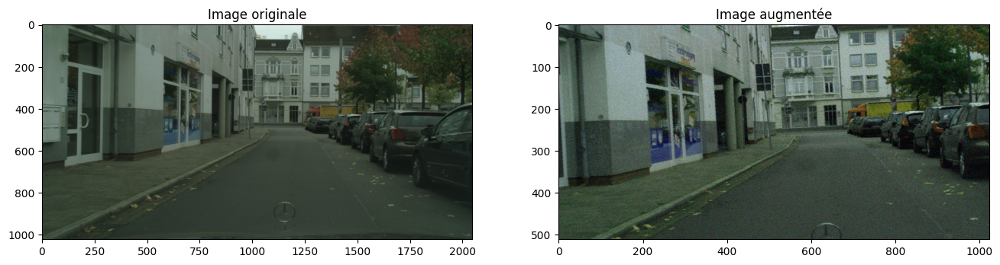

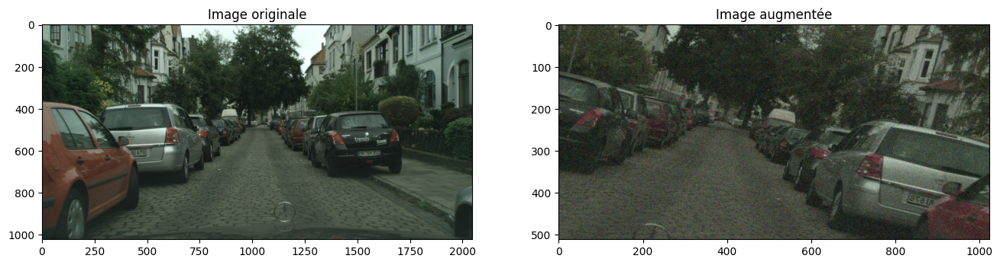

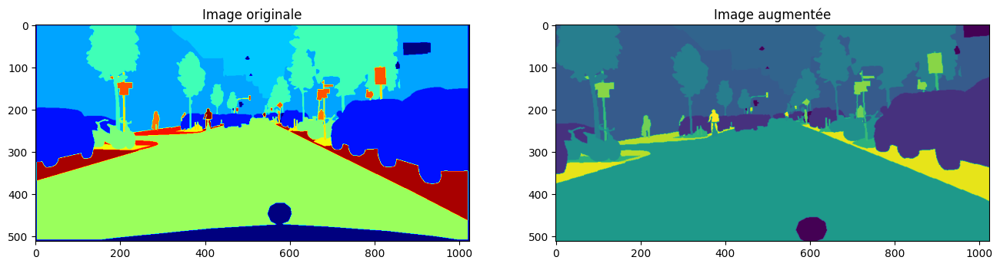

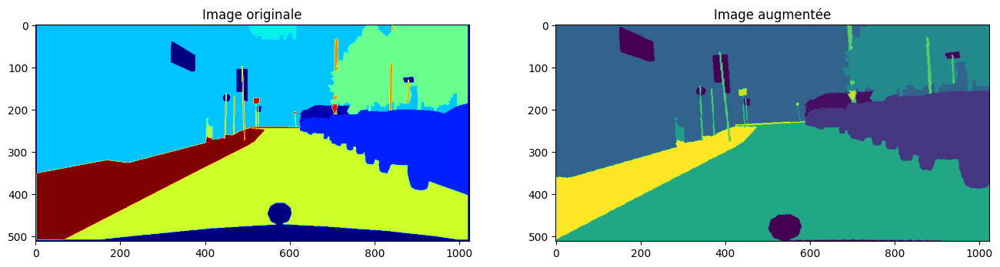

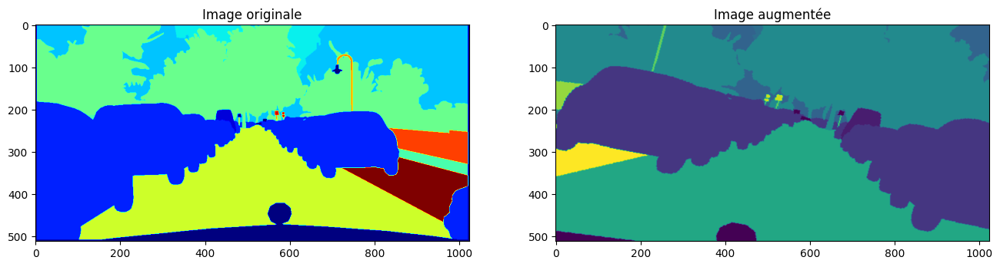

In [ ]:
# Affichez quelques exemples pour vérifier les données générées
i=0
for im in list_img:
  i+=1
  img0 = img_to_array(load_img(im, target_size=(1024, 2048)))
  theta = tf.random.stateless_uniform([1], seed=(i, 0), minval=-15, maxval=15, dtype=tf.float16).numpy()
  img0_aug = rotation(im, angle=theta)

  noise = tf.random.stateless_uniform([1], seed=(i, 0), minval=0, maxval=20, dtype=tf.float16).numpy()

  orig_h, orig_w, nb_can = img0_aug.shape
  scale_factor = tf.random.stateless_uniform([2], seed=(i, 0), minval=0.8, maxval=1, dtype=tf.float16).numpy()
  new_h, new_w = int(orig_h * scale_factor[0]), int(orig_w * scale_factor[1])
  img0_aug = tf.image.stateless_random_crop(img0_aug, (new_h, new_w, nb_can), seed=(i, 0))
  img0_aug = tf.image.resize(img0_aug, [512, 1024], method=tf.image.ResizeMethod.BILINEAR)
  img0_aug = tf.image.stateless_random_flip_left_right(img0_aug, seed=(i,0))
  img0_aug = tf.image.stateless_random_brightness(img0_aug, seed=(i,0), max_delta=10)
  img0_aug = tf.image.stateless_random_contrast(img0_aug, lower=0.5, upper=1.5, seed=(i, 0))
  img0_aug = tf.image.stateless_random_hue(img0_aug, max_delta=0.1, seed=(i, 0))
  img0_aug = tf.image.stateless_random_saturation(img0_aug, lower=0.8, upper=1.2, seed=(i, 0))
  img0_aug = img0_aug + tf.random.normal(shape=tf.shape(img0_aug), mean=0.0, stddev=noise, dtype=tf.float32)

  img0_aug = tf.clip_by_value(img0_aug, 0.0, 255.0)




  plt.figure(figsize=(16, 8))
  plt.subplot(1, 2, 1)
  plt.imshow(img0.astype('uint8'))
  plt.title('Image originale')

  plt.subplot(1, 2, 2)
  plt.imshow(img0_aug.numpy().astype('uint8'))  # Vous pouvez choisir une colormap adaptée à vos classes
  plt.title('Image augmentée')

  # plt.show()
  plt.savefig("./data_presentatation/{}".format(im.split("/")[-1]))


# Affichez quelques exemples pour vérifier les données générées
i = 0
for im in list_lab:
  i+=1
  img0 = img_to_array(load_img(im, target_size=(512, 1024), grayscale=True))
  theta = tf.random.stateless_uniform([1], seed=(i, 0), minval=-15, maxval=15, dtype=tf.float16).numpy()
  img0_aug = np.expand_dims(rotation(im, angle=theta)[:, :, 0], axis=2)

  orig_h, orig_w, nb_can = img0_aug.shape
  scale_factor = tf.random.stateless_uniform([2], seed=(i, 0), minval=0.8, maxval=1, dtype=tf.float16).numpy()
  new_h, new_w = int(orig_h * scale_factor[0]), int(orig_w * scale_factor[1])

  img0_aug = tf.image.stateless_random_crop(img0_aug, (new_h, new_w, nb_can), seed=(i, 0))
  img0_aug = tf.image.resize(img0_aug, [512, 1024], method=tf.image.ResizeMethod.BILINEAR)
  img0_aug = tf.image.stateless_random_flip_left_right(img0_aug, seed=(i,0))

  plt.figure(figsize=(16, 8))
  plt.subplot(1, 2, 1)
  plt.imshow(img0.astype('uint8'), cmap='jet')
  plt.title('Image originale')

  plt.subplot(1, 2, 2)
  plt.imshow(img0_aug.numpy().astype('uint8'))  # Vous pouvez choisir une colormap adaptée à vos classes
  plt.title('Image augmentée')

  # plt.show()
  plt.savefig("./data_presentatation/{}".format(im.split("/")[-1]))

In [ ]:
split_data_path = "{}/Split_data".format(projet_path)

# Images d'entrainement
img_train_dir = '{}/train/Images'.format(split_data_path)
lab_train_dir = '{}/train/Labels'.format(split_data_path)

# Image de validation
img_val_dir = '{}/val/Images'.format(split_data_path)
lab_val_dir = '{}/val/Labels'.format(split_data_path)

# Image de test
img_test_dir = '{}/test/Images'.format(split_data_path)
lab_test_dir = '{}/test/Labels'.format(split_data_path)

In [ ]:
param_unet = {
    "img_height": 256,
    "img_width": 512
}

param_train_gen = {
    "image_folder": img_train_dir,
    "mask_folder": lab_train_dir,
    "batch_size": 8,
    "img_height": 256,
    "img_width": 512
}

param_val_gen = {
    "image_folder": img_val_dir,
    "mask_folder": lab_val_dir,
    "batch_size": 8,
    "img_height": 256,
    "img_width": 512
}

param_fit = {
    "epochs": 25,
    "steps_per_epoch": len(os.listdir(param_train_gen['image_folder'])) // param_train_gen['batch_size'],
    "validation_steps": len(os.listdir(param_val_gen['image_folder'])) // param_val_gen['batch_size']
}


In [ ]:
with tf.keras.utils.custom_object_scope({'dice_coeff': dice_coeff, 'total_loss': total_loss}):
    model_unet = tf.keras.models.load_model("best_model_2_aug.h5")

# Afficher le résumé du modèle
model_unet.summary()

Un premier entraînement avec de fortes modifications dans les images d'entraînement.

In [ ]:
param_fit = {
    "epochs": 20,
    "steps_per_epoch": len(os.listdir(param_train_gen['image_folder'])) // param_train_gen['batch_size'],
    "validation_steps": len(os.listdir(param_val_gen['image_folder'])) // param_val_gen['batch_size']
}

# Créer des générateurs de données pour l'entraînement et la validation
train_generator = data_generator_aug(**param_train_gen)
val_generator = data_generator(**param_val_gen)


# model_unet.compile(optimizer=optimizer, loss=total_loss, metrics=[MeanIoU(num_classes=29)])
model_unet.compile(optimizer='adam', loss=total_loss, metrics=[dice_coeff, MeanIoU(num_classes=29)])

# Définition des callbacks
checkpoint = ModelCheckpoint("best_model_2_aug.h5", monitor="dice_coeff", mode="max", save_best_only=True)
early_stopping = EarlyStopping(monitor='dice_coeff', mode="max", patience=5, verbose=1)

# Entraînement du modèle avec les callbacks
history = model_unet.fit(train_generator, validation_data=val_generator, callbacks=[checkpoint, early_stopping], **param_fit)


Epoch 1/20
297/297 [==============================] - 1675s 6s/step - loss: 0.9990 - dice_coeff: 0.7289 - mean_io_u: 0.4728 - val_loss: 0.8389 - val_dice_coeff: 0.7750 - val_mean_io_u: 0.4742
Epoch 2/20
297/297 [==============================] - 594s 2s/step - loss: 0.9554 - dice_coeff: 0.7348 - mean_io_u: 0.4733 - val_loss: 0.8481 - val_dice_coeff: 0.7644 - val_mean_io_u: 0.4746
Epoch 3/20
297/297 [==============================] - 592s 2s/step - loss: 0.9370 - dice_coeff: 0.7351 - mean_io_u: 0.4736 - val_loss: 0.7747 - val_dice_coeff: 0.7817 - val_mean_io_u: 0.4751
Epoch 4/20
297/297 [==============================] - 588s 2s/step - loss: 0.9155 - dice_coeff: 0.7375 - mean_io_u: 0.4736 - val_loss: 0.8370 - val_dice_coeff: 0.7587 - val_mean_io_u: 0.4776
Epoch 5/20
297/297 [==============================] - 574s 2s/step - loss: 0.9128 - dice_coeff: 0.7350 - mean_io_u: 0.4735 - val_loss: 0.7845 - val_dice_coeff: 0.7714 - val_mean_io_u: 0.4747
Epoch 6/20
297/297 [========================

In [ ]:
with tf.keras.utils.custom_object_scope({'dice_coeff': dice_coeff, 'total_loss': total_loss}):
    model_unet = tf.keras.models.load_model("best_model_2_aug.h5")

# Afficher le résumé du modèle
model_unet.summary()

In [ ]:
model_complet = unet_view(model_unet)

In [ ]:
img_height, img_width = 256, 512


# Chargement et prétraitement d'une image pour la prédiction
image_path = os.path.join(img_test_dir, os.listdir(img_test_dir)[0])
img = load_img(image_path, target_size=(img_height, img_width))
img_array = img_to_array(img)
img_array = np.expand_dims(img_array, axis=0)  # Ajouter une dimension pour le lot (batch)

# Effectuer la prédiction
predicted_masks = model_complet.predict(img_array)

1/1 [==============================] - 3s 3s/step


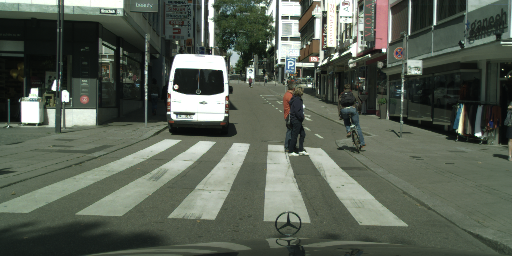

In [ ]:
img

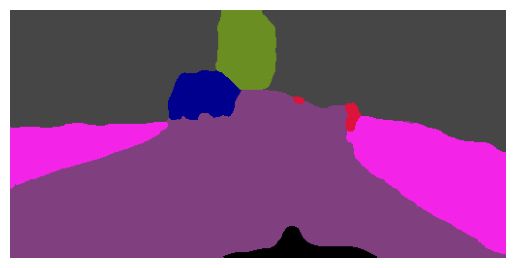

In [ ]:
predicted_masks = np.squeeze(predicted_masks)

import matplotlib.pyplot as plt

# Supposons que 'image_array' est le tableau NumPy obtenu après la transformation
# Assurez-vous que 'image_array' a la forme (img_height, img_width, 3)
plt.imshow(predicted_masks.astype('uint8'))
plt.axis('off')  # Masquer les axes
plt.show()

On peut constater qu'il y a de fortes baisses de performances par rapport au fait de ne pas utiliser l'augmentation de données.

Cela peut-être dû au fait que nous effectuons des modifications importantes sur le jeu de données qui s'éloigne trop des données à prédire.

Le modèle sera peut être plus performant pour des photos prises au hasard dans la ville. Cependant, dans notre cas, toutes les photos sont prises sous un mêmes angle dans des conditions similaires avec un devant de voiture en bas de l'image.

On va donc relancer l'entraînement en repartant du modèle de base, mais avec des données moins modifiées.

In [ ]:
with tf.keras.utils.custom_object_scope({'dice_coeff': dice_coeff, 'total_loss': total_loss}):
    model_unet = tf.keras.models.load_model("best_model_2_aug_2.h5")

# Afficher le résumé du modèle
# model_unet.summary()

1 ème lancement

In [ ]:
param_fit = {
    "epochs": 15,
    "steps_per_epoch": len(os.listdir(param_train_gen['image_folder'])) // param_train_gen['batch_size'],
    "validation_steps": len(os.listdir(param_val_gen['image_folder'])) // param_val_gen['batch_size']
}

# Créer des générateurs de données pour l'entraînement et la validation
train_generator = data_generator_aug(**param_train_gen)
val_generator = data_generator(**param_val_gen)


# model_unet.compile(optimizer=optimizer, loss=total_loss, metrics=[MeanIoU(num_classes=29)])
model_unet.compile(optimizer='adam', loss=total_loss, metrics=[dice_coeff, MeanIoU(num_classes=29)])

# Définition des callbacks
checkpoint = ModelCheckpoint("best_model_2_aug_2.h5", monitor="dice_coeff", mode="max", save_best_only=True)
early_stopping = EarlyStopping(monitor='dice_coeff', mode="max", patience=5, verbose=1)

# Entraînement du modèle avec les callbacks
history = model_unet.fit(train_generator, validation_data=val_generator, callbacks=[checkpoint, early_stopping], **param_fit)


Epoch 1/15
297/297 [==============================] - 3473s 12s/step - loss: 0.9630 - dice_coeff: 0.7894 - mean_io_u: 0.4738 - val_loss: 0.7127 - val_dice_coeff: 0.8419 - val_mean_io_u: 0.4870
Epoch 2/15
297/297 [==============================] - 960s 3s/step - loss: 0.8688 - dice_coeff: 0.7962 - mean_io_u: 0.4779 - val_loss: 0.6872 - val_dice_coeff: 0.8442 - val_mean_io_u: 0.4940
Epoch 3/15
297/297 [==============================] - 959s 3s/step - loss: 0.8108 - dice_coeff: 0.8015 - mean_io_u: 0.4788 - val_loss: 0.6656 - val_dice_coeff: 0.8382 - val_mean_io_u: 0.4898
Epoch 4/15
297/297 [==============================] - 948s 3s/step - loss: 0.7713 - dice_coeff: 0.8048 - mean_io_u: 0.4789 - val_loss: 0.6141 - val_dice_coeff: 0.8467 - val_mean_io_u: 0.4909
Epoch 5/15
297/297 [==============================] - 916s 3s/step - loss: 0.7516 - dice_coeff: 0.8038 - mean_io_u: 0.4791 - val_loss: 0.5869 - val_dice_coeff: 0.8511 - val_mean_io_u: 0.4908
Epoch 6/15
297/297 [=======================

In [ ]:
with tf.keras.utils.custom_object_scope({'dice_coeff': dice_coeff, 'total_loss': total_loss}):
    model_unet = tf.keras.models.load_model("best_model_2_aug_2.h5")

# Afficher le résumé du modèle
# model_unet.summary()

In [ ]:
model_complet = unet_view(model_unet)

In [ ]:
img_height, img_width = 256, 512


# Chargement et prétraitement d'une image pour la prédiction
image_path = os.path.join(img_test_dir, os.listdir(img_test_dir)[0])
img = load_img(image_path, target_size=(img_height, img_width))
img_array = img_to_array(img)
img_array = np.expand_dims(img_array, axis=0)  # Ajouter une dimension pour le lot (batch)

# Effectuer la prédiction
predicted_masks = model_complet.predict(img_array)

1/1 [==============================] - 5s 5s/step


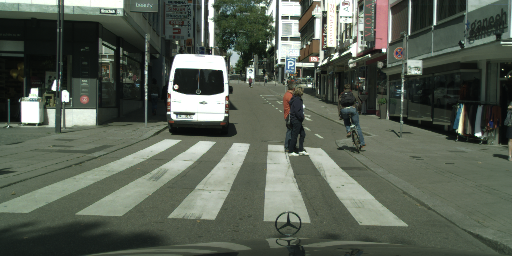

In [ ]:
img

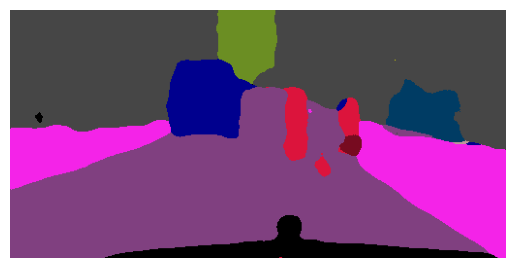

In [ ]:
predicted_masks = np.squeeze(predicted_masks)

import matplotlib.pyplot as plt

# Supposons que 'image_array' est le tableau NumPy obtenu après la transformation
# Assurez-vous que 'image_array' a la forme (img_height, img_width, 3)
plt.imshow(predicted_masks.astype('uint8'))
plt.axis('off')  # Masquer les axes
plt.show()

In [ ]:
with tf.keras.utils.custom_object_scope({'dice_coeff': dice_coeff, 'total_loss': total_loss}):
    model_unet = tf.keras.models.load_model("best_model_2_aug_2.h5")

# Afficher le résumé du modèle
# model_unet.summary()

2 ème lancement

In [ ]:
param_fit = {
    "epochs": 10,
    "steps_per_epoch": len(os.listdir(param_train_gen['image_folder'])) // param_train_gen['batch_size'],
    "validation_steps": len(os.listdir(param_val_gen['image_folder'])) // param_val_gen['batch_size']
}

# Créer des générateurs de données pour l'entraînement et la validation
train_generator = data_generator_aug(**param_train_gen)
val_generator = data_generator(**param_val_gen)


# model_unet.compile(optimizer=optimizer, loss=total_loss, metrics=[MeanIoU(num_classes=29)])
model_unet.compile(optimizer='adam', loss=total_loss, metrics=[dice_coeff, MeanIoU(num_classes=29)])

# Définition des callbacks
checkpoint = ModelCheckpoint("best_model_2_aug_3.h5", monitor="dice_coeff", mode="max", save_best_only=True)
early_stopping = EarlyStopping(monitor='dice_coeff', mode="max", patience=5, verbose=1)

# Entraînement du modèle avec les callbacks
history = model_unet.fit(train_generator, validation_data=val_generator, callbacks=[checkpoint, early_stopping], **param_fit)


Epoch 1/10
297/297 [==============================] - 1640s 5s/step - loss: 0.6623 - dice_coeff: 0.8096 - mean_io_u: 0.4804 - val_loss: 0.5985 - val_dice_coeff: 0.8269 - val_mean_io_u: 0.5020
Epoch 2/10
297/297 [==============================] - 944s 3s/step - loss: 0.6583 - dice_coeff: 0.8081 - mean_io_u: 0.4804 - val_loss: 0.5258 - val_dice_coeff: 0.8470 - val_mean_io_u: 0.4872
Epoch 3/10
297/297 [==============================] - 937s 3s/step - loss: 0.6397 - dice_coeff: 0.8118 - mean_io_u: 0.4817 - val_loss: 0.5397 - val_dice_coeff: 0.8408 - val_mean_io_u: 0.4826
Epoch 4/10
297/297 [==============================] - 945s 3s/step - loss: 0.6417 - dice_coeff: 0.8098 - mean_io_u: 0.4818 - val_loss: 0.5410 - val_dice_coeff: 0.8401 - val_mean_io_u: 0.4837
Epoch 5/10
297/297 [==============================] - 932s 3s/step - loss: 0.6242 - dice_coeff: 0.8139 - mean_io_u: 0.4810 - val_loss: 0.4759 - val_dice_coeff: 0.8582 - val_mean_io_u: 0.4850
Epoch 6/10
297/297 [========================

In [ ]:
with tf.keras.utils.custom_object_scope({'dice_coeff': dice_coeff, 'total_loss': total_loss}):
    model_unet = tf.keras.models.load_model("best_model_2_aug_3.h5")

# Afficher le résumé du modèle
# model_unet.summary()

In [ ]:
model_complet = unet_view(model_unet)

In [ ]:
img_height, img_width = 256, 512


# Chargement et prétraitement d'une image pour la prédiction
image_path = os.path.join(img_test_dir, os.listdir(img_test_dir)[0])
img = load_img(image_path, target_size=(img_height, img_width))
img_array = img_to_array(img)
img_array = np.expand_dims(img_array, axis=0)  # Ajouter une dimension pour le lot (batch)

# Effectuer la prédiction
predicted_masks = model_complet.predict(img_array)

1/1 [==============================] - 1s 542ms/step


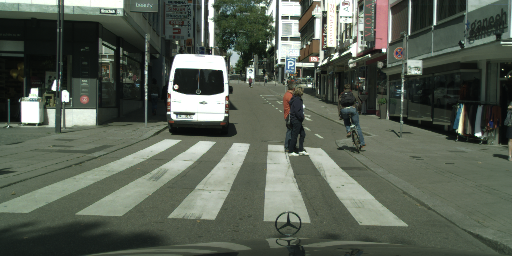

In [ ]:
img

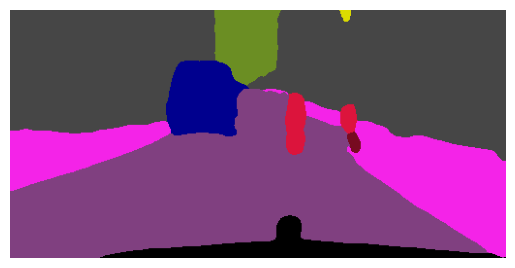

In [ ]:
predicted_masks = np.squeeze(predicted_masks)

import matplotlib.pyplot as plt

# Supposons que 'image_array' est le tableau NumPy obtenu après la transformation
# Assurez-vous que 'image_array' a la forme (img_height, img_width, 3)
plt.imshow(predicted_masks.astype('uint8'))
plt.axis('off')  # Masquer les axes
plt.show()

In [ ]:
with tf.keras.utils.custom_object_scope({'dice_coeff': dice_coeff, 'total_loss': total_loss}):
    model_unet = tf.keras.models.load_model("best_model_2_aug_3.h5")

# Afficher le résumé du modèle
# model_unet.summary()

Ici les résultats, sont bien meilleurs avec les données légèrement modifiées. Les résultats en terme de métrique sont similaire à l'entraînement sans augmentation de données. On peut noter cependant, que le modèle avait ici un handicap avec le cadre de la voiture en bas de l'image qui pouvait varier du fait de la modification des données, ce qui n'était pas le cas avant et qui donc était facile à prédire.

## Conclusion : Comparaisons des différents résultats d'entraînement du modèle <a class="anchor" id="partie4"></a>

In [7]:
split_data_path = "{}/Split_data".format(projet_path)

# Image de test
img_test_dir = '{}/test/Images'.format(split_data_path)
lab_test_dir = '{}/test/Labels'.format(split_data_path)

In [8]:
param_test_gen = {
    "image_folder": img_test_dir,
    "mask_folder": lab_test_dir,
    "batch_size": 8,
    "img_height": 256,
    "img_width": 512
}


test_generator = data_generator(**param_test_gen)

In [10]:
steps_per_epoch = len(os.listdir(param_test_gen['image_folder'])) // param_test_gen['batch_size']

In [9]:
with tf.keras.utils.custom_object_scope({'dice_coeff': dice_coeff, 'total_loss': total_loss}):
    model_unet_base = tf.keras.models.load_model("best_model.h5")

    model_unet_2 = tf.keras.models.load_model("best_model_2.h5")

    model_unet_aug_brut = tf.keras.models.load_model("best_model_2_aug.h5")

    model_unet_aug_fin_1 = tf.keras.models.load_model("best_model_2_aug_2.h5")

    model_unet_aug_fin_2 = tf.keras.models.load_model("best_model_2_aug_3.h5")

In [14]:
# Assuming you have a test_dataset variable
test_results_base = model_unet_base.evaluate(test_generator, steps=steps_per_epoch)

test_results_2 = model_unet_2.evaluate(test_generator, steps=steps_per_epoch)

test_results_brut = model_unet_aug_brut.evaluate(test_generator, steps=steps_per_epoch)

test_results_fin_1 = model_unet_aug_fin_1.evaluate(test_generator, steps=steps_per_epoch)

test_results_fin_2 = model_unet_aug_fin_2.evaluate(test_generator, steps=steps_per_epoch)

37/37 [==============================] - 36s 979ms/step - loss: 0.5117 - dice_coeff: 0.8472 - mean_io_u: 0.4854


In [22]:
indx = ["adam", 'total_loss', 'dice_coeff', 'mean_io_u']

res_base = [test_results_base[0], None, test_results_base[1], None]
res_2 = [test_results_2[0], None, test_results_2[1], test_results_2[2]]
res_brut = [None, test_results_brut[0], test_results_brut[1], test_results_brut[2]]
res_fin_1 = [None, test_results_fin_1[0], test_results_fin_1[1], test_results_fin_1[2]]
res_fin_2 = [None, test_results_fin_2[0], test_results_fin_2[1], test_results_fin_2[2]]

In [31]:
dic = {
    "model_unet_base": res_base,
    'model_unet_2': res_2,
    'model_unet_aug_brut': res_brut,
    'model_unet_aug_fin_1': res_fin_1,
    'model_unet_aug_fin_2': res_fin_2
    }
res_total = pd.DataFrame(dic, index=indx).transpose()
res_total = res_total.mask(pd.isnull(res_total), np.nan)
res_total

,adam,total_loss,dice_coeff,mean_io_u
model_unet_base,0.401552,NaN,0.837783,NaN
model_unet_2,0.379151,NaN,0.891156,0.516906
model_unet_aug_brut,NaN,0.748099,0.772534,0.470940
model_unet_aug_fin_1,NaN,0.534988,0.850591,0.495585
model_unet_aug_fin_2,NaN,0.511709,0.847202,0.485412


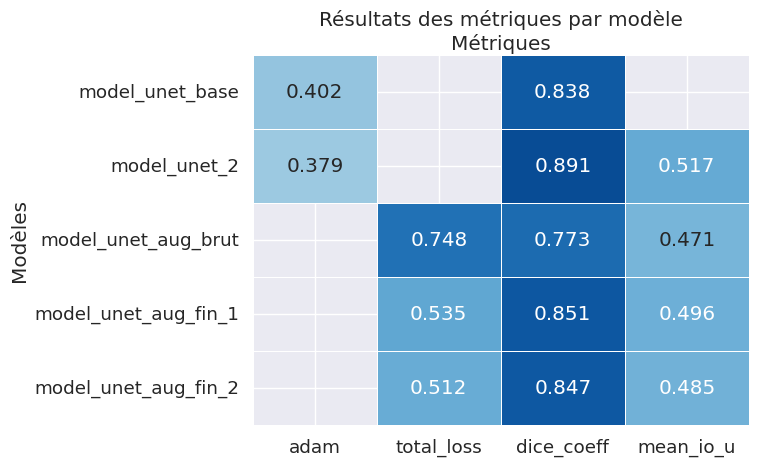

In [37]:
plt.figure(dpi=100)
sns.set(font_scale=1.2)
heatmap = sns.heatmap(res_total, annot=True, cmap='Blues', fmt=".3f", linewidths=0.5, cbar=False, vmin=0, vmax=1)
heatmap.xaxis.set_label_position('top')

# Réglez les étiquettes et le titre
plt.xlabel("Métriques")
plt.ylabel("Modèles")
plt.title("Résultats des métriques par modèle")

# Affichez le graphique
# plt.show()
plt.savefig("./data_presentatation/res/comparaison_res.png")

In [10]:
model_unet_base = unet_view(model_unet_base)
model_unet_2 = unet_view(model_unet_2)
model_unet_aug_brut = unet_view(model_unet_aug_brut)
model_unet_aug_fin_1 = unet_view(model_unet_aug_fin_1)
model_unet_aug_fin_2 = unet_view(model_unet_aug_fin_2)

In [11]:
images = np.random.choice(os.listdir(img_test_dir), 5, replace=False)
images

array(['bremen_000145_000019_leftImg8bit.png',
       'darmstadt_000076_000019_leftImg8bit.png',
       'dusseldorf_000139_000019_leftImg8bit.png',
       'hamburg_000000_095561_leftImg8bit.png',
       'aachen_000159_000019_leftImg8bit.png'], dtype='<U45')

In [12]:
labels = [os.path.join(lab_test_dir, file[:-16]) + '_gtFine_color_converted.png' for file in images]
labels

['/content/drive/MyDrive/P8/Split_data/test/Labels/bremen_000145_000019_gtFine_color_converted.png',
 '/content/drive/MyDrive/P8/Split_data/test/Labels/darmstadt_000076_000019_gtFine_color_converted.png',
 '/content/drive/MyDrive/P8/Split_data/test/Labels/dusseldorf_000139_000019_gtFine_color_converted.png',
 '/content/drive/MyDrive/P8/Split_data/test/Labels/hamburg_000000_095561_gtFine_color_converted.png',
 '/content/drive/MyDrive/P8/Split_data/test/Labels/aachen_000159_000019_gtFine_color_converted.png']

In [25]:
original_color = {
    '0': [0, 0, 0], '1': [0, 0, 70], '2': [0, 0, 90], '3': [0, 0, 110], '4': [0, 0, 142], '5': [0, 0, 230],
    '6': [0, 60, 100], '7': [0, 80, 100], '8': [70, 70, 70], '9': [70, 130, 180], '10': [81, 0, 81],
    '11': [102, 102, 156], '12': [107, 142, 35], '13': [111, 74, 0], '14': [119, 11, 32], '15': [128, 64, 128],
    '16': [150, 100, 100], '17': [150, 120, 90], '18': [152, 251, 152], '19': [153, 153, 153], '20': [180, 165, 180],
    '21': [190, 153, 153], '22': [220, 20, 60], '23': [220, 220, 0], '24': [230, 150, 140], '25': [244, 35, 232],
    '26': [250, 170, 30], '27': [250, 170, 160], '28': [255, 0, 0]
}

In [47]:
img_height, img_width = 256, 512

batch_im = []
batch_masques = []
# Chargement et prétraitement de quelques images pour la prédiction
for im, lab in zip(images, labels):
  image_path = os.path.join(img_test_dir, im)
  img = load_img(image_path, target_size=(img_height, img_width))
  img_array = img_to_array(img)
  msq_array = img_to_array(load_img(lab, target_size=(img_height, img_width), grayscale=True))
  msq_array = np.array(pd.DataFrame(msq_array.squeeze()).applymap(lambda x: original_color[str(int(x))]).values.tolist())

  batch_masques.append(msq_array)
  batch_im.append(img_array.astype('int32'))

batch_im = np.array(batch_im)
batch_masques = np.array(batch_masques)

In [18]:
batch_im.shape

(5, 256, 512, 3)

In [21]:
pred_model_unet_base = model_unet_base.predict(batch_im)
pred_model_unet_2 = model_unet_2.predict(batch_im)
pred_model_unet_aug_brut = model_unet_aug_brut.predict(batch_im)
pred_model_unet_aug_fin_1 = model_unet_aug_fin_1.predict(batch_im)
pred_model_unet_aug_fin_2 = model_unet_aug_fin_2.predict(batch_im)

1/1 [==============================] - 0s 237ms/step


In [ ]:
original_image = img_to_array(load_img(lab, target_size=))

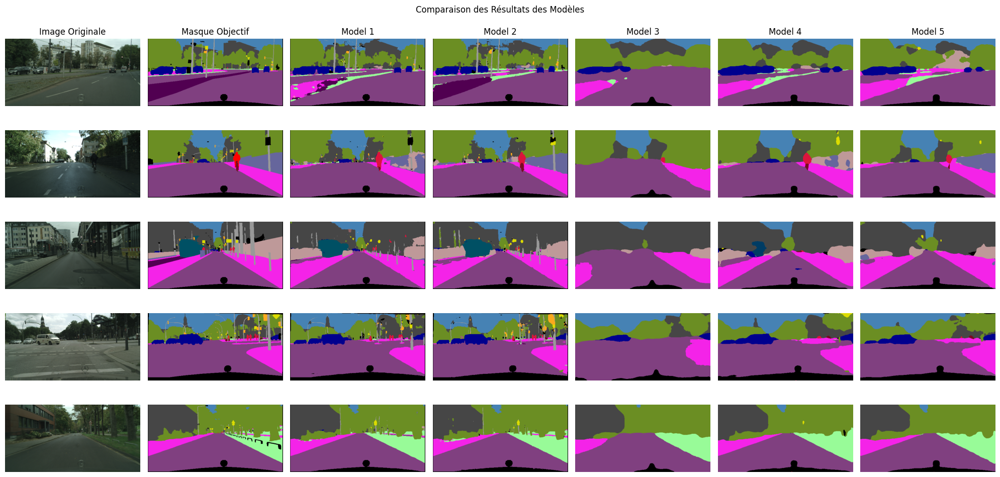

In [59]:
# Créez une figure avec plusieurs sous-graphiques (une rangée de 7 colonnes)
fig, axes = plt.subplots(5, 7, figsize=(20, 10))  # Augmentez le nombre de lignes pour inclure plus d'images de modèles

# Modèles prédits
predicted_models = [pred_model_unet_base, pred_model_unet_2, pred_model_unet_aug_brut, pred_model_unet_aug_fin_1, pred_model_unet_aug_fin_2]
model_names = ["Base", "Model 2", "Augmentation Brut", "Augmentation Fin 1", "Augmentation Fin 2"]

for i, pred in enumerate(predicted_models):
    for j in range(5):  # Boucle sur les indices j pour les lignes
        axes[j, i+2].imshow(pred[j], cmap='viridis')  # Utilisez axes[j, i] pour accéder au sous-graphique approprié
        if j == 0:
            axes[j, i+2].set_title(f"Model {i+1}")  # N'affichez le titre que sur la première ligne
        axes[j, i+2].axis('off')

# Image originale
for j in range(5):  # Boucle sur les indices j pour les lignes
    axes[j, 0].imshow(batch_im[j], cmap='viridis')  # Utilisez axes[j, 5] pour accéder au sous-graphique approprié
    if j == 0:
        axes[j, 0].set_title("Image Originale")  # N'affichez le titre que sur la première ligne
    axes[j, 0].axis('off')

# Masque objectif
for j in range(5):  # Boucle sur les indices j pour les lignes
    axes[j, 1].imshow(batch_masques[j], cmap='viridis')  # Utilisez axes[j, 6] pour accéder au sous-graphique approprié
    if j == 0:
        axes[j, 1].set_title("Masque Objectif")  # N'affichez le titre que sur la première ligne
    axes[j, 1].axis('off')

# Ajoutez un titre global à la figure
fig.suptitle("Comparaison des Résultats des Modèles")

# Réglez l'espacement entre les sous-graphiques
plt.tight_layout()

# Affichez la figure
# plt.show()
plt.savefig("./data_presentatation/res/image_res_0.png")


On garde les meilleurs modèles pour la comparaison.

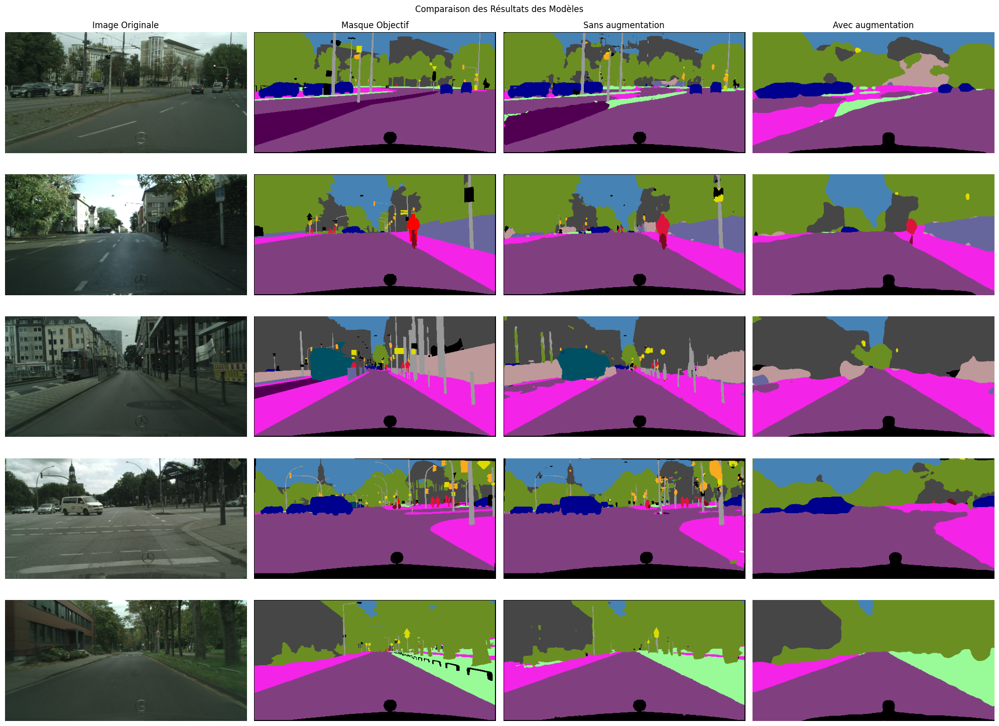

In [71]:
# Créez une figure avec plusieurs sous-graphiques (une rangée de 7 colonnes)
fig, axes = plt.subplots(5, 4, figsize=(20, 15))  # Augmentez le nombre de lignes pour inclure plus d'images de modèles

# Modèles prédits
predicted_models = [pred_model_unet_2, pred_model_unet_aug_fin_2]
model_names = ["Sans augmentation", "Avec augmentation"]

for i, pred in enumerate(predicted_models):
    for j in range(5):  # Boucle sur les indices j pour les lignes
        axes[j, i+2].imshow(pred[j], cmap='viridis')  # Utilisez axes[j, i] pour accéder au sous-graphique approprié
        if j == 0:
            axes[j, i+2].set_title(model_names[i])  # N'affichez le titre que sur la première ligne
        axes[j, i+2].axis('off')

# Image originale
for j in range(5):  # Boucle sur les indices j pour les lignes
    axes[j, 0].imshow(batch_im[j], cmap='viridis')  # Utilisez axes[j, 3] pour accéder au sous-graphique approprié
    if j == 0:
        axes[j, 0].set_title("Image Originale")  # N'affichez le titre que sur la première ligne
    axes[j, 0].axis('off')

# Masque objectif
for j in range(5):  # Boucle sur les indices j pour les lignes
    axes[j, 1].imshow(batch_masques[j], cmap='viridis')  # Utilisez axes[j, 4] pour accéder au sous-graphique approprié
    if j == 0:
        axes[j, 1].set_title("Masque Objectif")  # N'affichez le titre que sur la première ligne
    axes[j, 1].axis('off')

# Ajoutez un titre global à la figure
fig.suptitle("Comparaison des Résultats des Modèles")

# Réglez l'espacement entre les sous-graphiques
plt.tight_layout()

# Affichez la figure
# plt.show()
plt.savefig("./data_presentatation/res/image_res_1.png")
